In [2]:
import pandas as pd
import numpy as np

In [4]:
data = "/home/asus/Machine-Learning/ml-zoomcamp-2k26/module_2_regression/datasets/car_fuel_efficiency_2026.csv"

df = pd.read_csv(data)
df

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2005,USA,Gasoline,All-wheel drive,4,2470,6,271.0,4690,18.9,27.4
9996,1993,Asia,Gasoline,All-wheel drive,2,2300,6,244.0,4370,19.0,30.0
9997,2014,USA,Gasoline,All-wheel drive,3,2480,6,267.0,4590,18.4,28.1
9998,2004,USA,Hybrid,Rear-wheel drive,5,2180,6,270.0,4450,20.9,32.2


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

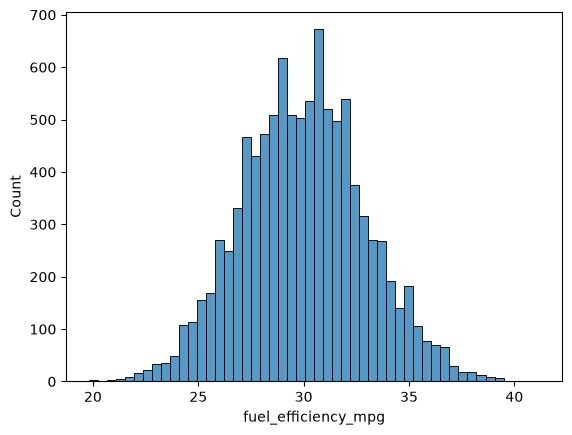

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.histplot(df.fuel_efficiency_mpg, bins = 50)

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

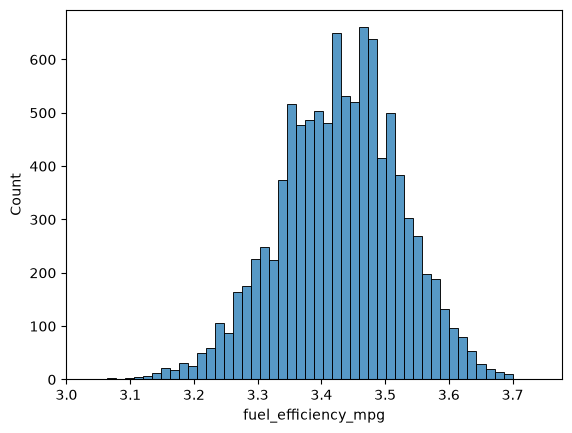

In [6]:
log_plot_mpg = np.log1p(df.fuel_efficiency_mpg)
sns.histplot(log_plot_mpg, bins = 50)

In [7]:
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [10]:
cols = list(df.columns[df.isnull().sum() > 0])
for col in cols:
    df[col] = df[col].fillna(df[col].median())
df.isnull().sum()

model_year             0
origin                 0
fuel_type              0
drivetrain             0
num_doors              0
engine_displacement    0
num_cylinders          0
horsepower             0
vehicle_weight         0
acceleration           0
fuel_efficiency_mpg    0
dtype: int64

In [11]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,18.9,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,18.9,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [13]:
n = len(df)

n_train = int(0.6 * n)
n_val = int(0.2 * n)
n_test = n - n_train - n_val

print(n, n_train, n_val, n_test)

10000 6000 2000 2000


In [15]:
idx = np.arange(n)
np.random.seed(42)
np.random.shuffle(idx)
idx

array([6252, 4684, 1731, ..., 5390,  860, 7270], shape=(10000,))

In [17]:
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train : n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val : ]]

df_train

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
6252,2015,USA,Diesel,Front-wheel drive,3,1900,5,239.0,3790,20.3,32.5
4684,1992,USA,Gasoline,All-wheel drive,4,2000,6,224.0,4380,21.8,29.1
1731,2022,USA,Hybrid,Front-wheel drive,3,2330,6,286.0,4090,17.8,34.1
4742,1997,Asia,Gasoline,Front-wheel drive,5,2300,6,254.0,4150,19.9,30.6
4521,2001,USA,Gasoline,Front-wheel drive,4,2340,6,269.0,4400,18.6,30.7
...,...,...,...,...,...,...,...,...,...,...,...
7895,2018,Asia,Gasoline,Rear-wheel drive,4,2280,6,242.0,4590,20.5,29.8
9590,1984,Europe,Gasoline,Front-wheel drive,2,2300,6,254.0,4240,18.1,25.1
7288,1989,USA,Gasoline,Front-wheel drive,3,2240,6,255.0,4190,17.2,27.7
278,2020,Europe,Gasoline,Rear-wheel drive,5,2430,6,254.0,4280,18.4,31.6


In [19]:
df['horsepower'].median()
# Ques-2

np.float64(254.0)

In [28]:
df = pd.read_csv(data)
for col in cols:
    df[col] = df[col].fillna(df_train[col].mean()) # specially mentioned to use df_train thats why i used this

idx = np.arange(n)
np.random.seed(42)
np.random.shuffle(idx)
    
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train : n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val : ]]

In [29]:
y_train = df_train['fuel_efficiency_mpg'].values
y_val = df_val['fuel_efficiency_mpg'].values
y_test = df_test['fuel_efficiency_mpg'].values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [31]:
df['model_year'].max().item()

2024

In [35]:
base = ['engine_displacement',
'horsepower',
'vehicle_weight']


def prepare_X(df):
    df = df.copy()
    df['age'] = 2024 - df['model_year']
    features = base + ['age']
    X = df[features].values
    return X


def train_linear_regression(X, y):
    ones = np.ones(len(X))
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]

X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)

y_pred = w0 + X_val.dot(w)
y_pred

array([31.54288381, 29.92505124, 31.56459528, ..., 30.54408314,
       30.85701231, 31.55313728], shape=(2000,))

In [38]:
def rmse(y_pred, y):
    val = (y - y_pred)**2
    val = val.mean()
    return np.sqrt(val)

round(rmse(y_val, y_pred), 3).item()

2.202

In [40]:
# now based on the demand of question let's do all the above activities by filling the empty values with "0"...

for col in cols:
    df[col] = df[col].fillna(0) # specially mentioned to use df_train thats why i used this

idx = np.arange(n)
np.random.seed(42)
np.random.shuffle(idx)
    
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train : n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val : ]]


del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)

y_pred = w0 + X_val.dot(w)

round(rmse(y_val, y_pred), 3).item()

2.202

In [57]:
# Both are equally good

# Now use Regularization

def train_linear_regression(X, y, r):
    ones = np.ones(len(X))
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX = XTX + r*np.eye(len(XTX))
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]


r = [0, 0.01, 0.1, 1, 5, 10, 100]
best_r = r[0]
best_score = 2.202
rmse_list = []
for r_val in r:
    w0, w = train_linear_regression(X_train, y_train, r_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)
    score = round(score, 4)
    rmse_list.append(score.item())
    if(score <= best_score):
        if(score == best_score):
            best_r = min(best_r, r_val)
        else:
            best_r = r_val
            best_score = score
    

print(rmse_list, "\n", best_r)   

# Ques 4

[2.2018, 2.2018, 2.2015, 2.2031, 2.2695, 2.4041, 3.4171] 
 0.1


In [71]:
seed = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

# Again define the without train_linear_regression()
def train_linear_regression(X, y):
    ones = np.ones(len(X))
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]


def set_dataframe_with_diff_seed(df, seed):
    idx = np.arange(len(df))
    np.random.seed(seed)
    np.random.shuffle(idx)
        
    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train : n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val : ]]

    y_train = df_train['fuel_efficiency_mpg'].values
    y_val = df_val['fuel_efficiency_mpg'].values
    y_test = df_test['fuel_efficiency_mpg'].values
    
    
    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    return df_train, df_val, df_test, y_train, y_val, y_test


rmse_list = []
for s in seed:
    df_train, df_val, df_test, y_train, y_val, y_test = set_dataframe_with_diff_seed(df, s)
    X_train = prepare_X(df_train)
    X_val = prepare_X(df_val)
    
    w0, w = train_linear_regression(X_train, y_train)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)
    rmse_list.append(score.item())

result = round(np.std(rmse_list), 3).item()
print("rmse_values =", [round(x, 3) for x in rmse_list])
print("Standard_Deviation =", result)

# Ques 5

rmse_values = [2.236, 2.196, 2.159, 2.204, 2.199, 2.241, 2.264, 2.186, 2.218, 2.204]
Standard_Deviation = 0.029


In [74]:
def train_linear_regression(X, y, r):
    ones = np.ones(len(X))
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX = XTX + r*np.eye(len(XTX))
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]

# at last the seed value set as 9 as it was the last element in that list so no need to simulate things again for seed 9

X_test = prepare_X(df_test)
w0, w = train_linear_regression(X_train, y_train, 0.001)
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)
print(score)

# Ques 6

2.230624509666738
